 BÀI 3 — PHÁT HIỆN CẠNH BẰNG GRADIENT RỜI RẠC
 Ảnh xám I là mảng NumPy 2 chiều. Mỗi pixel có giá trị trong [0, 255].
 Ảnh kiểm thử 100×100 có một hình chữ nhật sáng nên có cạnh theo cả hai hướng.
 Yêu cầu:
 1. Hoàn thiện compute_x_derivative(image): tại pixel (i,j) bên trong ảnh,
    Gx[i,j] = I[i,j+1] - I[i,j-1] (sai phân trung tâm theo cột).
 2. Hoàn thiện compute_y_derivative(image):
    Gy[i,j] = I[i+1,j] - I[i-1,j] (sai phân trung tâm theo hàng).
 3. Hoàn thiện compute_magnitude(image) = sqrt(Gx**2 + Gy**2),
    sử dụng chính hai hàm đã viết. Biên ngoài của Gx và Gy giữ bằng 0.
 4. Chuyển ảnh sang kiểu số có dấu / float trước khi trừ để tránh uint8 tràn.
    Không dùng cv2.Sobel, cv2.filter2D hoặc np.gradient.
 5. Chạy phần có sẵn để xem ảnh gốc, Gx, Gy, độ lớn gradient;
    mô tả cạnh dọc và cạnh ngang tương ứng với Gx hay Gy. Trả lời: ...


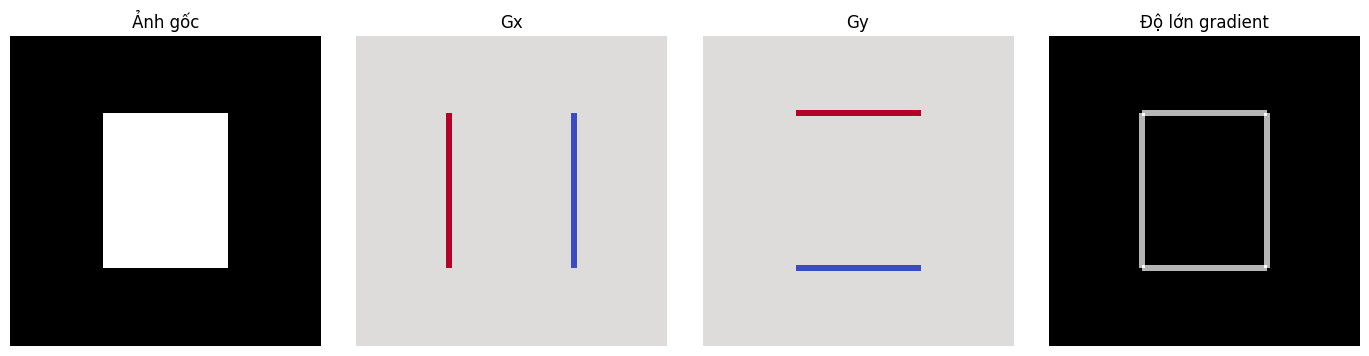

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def compute_x_derivative(image):
    image = np.asarray(image, dtype=float)
    gx = np.zeros_like(image)
    # your code here
    gx[:,1:-1]=image[:,2:]-image[:,:-2]
    return gx

def compute_y_derivative(image):
    image = np.asarray(image, dtype=float)
    gy = np.zeros_like(image)
    # your code here
    gy[1:-1,:]=image[2:,:]-image[:-2,:]
    return gy

def compute_magnitude(image):
    # your code here
    gx=compute_x_derivative(image)
    gy=compute_y_derivative(image)
    return np.hypot(gx,gy)
image = np.zeros((100, 100), dtype=np.uint8)
image[25:75, 30:70] = 200
gx = compute_x_derivative(image)
gy = compute_y_derivative(image)
magnitude = compute_magnitude(image)
assert gx.shape == gy.shape == magnitude.shape == image.shape
assert np.allclose(gx[:, [0, -1]], 0) and np.allclose(gy[[0, -1], :], 0)
assert np.any(gx != 0) and np.any(gy != 0)
assert np.allclose(magnitude, np.hypot(gx, gy))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, arr, title, cmap in zip(
    axes, [image, gx, gy, magnitude],
    ["Ảnh gốc", "Gx", "Gy", "Độ lớn gradient"],
    ["gray", "coolwarm", "coolwarm", "gray"]):
    ax.imshow(arr, cmap=cmap); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()